In [ ]:
from pathlib import Path
import pandas as pd
import sys

In [ ]:
DATA_DIR = Path("data")
region = "global"

charts = pd.read_csv(DATA_DIR / f"spotify_daily_{region}.csv", dtype={
    "region": str, "previous_rank": int, "peak_rank": int, "days_on_chart": int, "streams": int,
    "track_name": str, "artists": str, "track_uri": str, "labels": str}, parse_dates=["date", "release_date"])

## Calendar heatmaps: Christmas on Spotify's global top 100

Two charts from the global daily chart (`pull_spotify_charts.py`), each with one row per season from 25 October to 7 January and Christmas Day outlined:

1. **All I Want for Christmas Is You**, coloured by its position in the top 100, with the number of days it spent there each season on the right.
2. **Christmas songs in the top 100**, coloured by how many Christmas songs were in the top 100 that day, with the number of days with at least one Christmas song on the right.

In [ ]:
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Rectangle

# bwcharts isn't installed in this venv, so load it straight from its folder
BWCHARTS_DIR = r"C:\Users\Harry Turner\Documents\bwcharts"
if BWCHARTS_DIR not in sys.path:
    sys.path.insert(0, BWCHARTS_DIR)
import bwcharts as bw

# Mariah Carey's original only (matching on the URI leaves out the Justin Bieber duet and covers)
MARIAH_URI = "spotify:track:0bYg9bo50gSsH3LtXe2SQn"
mariah_rank = charts.loc[charts["track_uri"] == MARIAH_URI].set_index("date")["rank"]

# one row per chart day: the season it belongs to (named by its October year) and days since 1 Oct
cal = pd.DataFrame({"date": pd.DatetimeIndex(sorted(charts["date"].unique()))})
cal["season"] = np.where(cal["date"].dt.month >= 10, cal["date"].dt.year, cal["date"].dt.year - 1)
cal["day"] = (cal["date"] - pd.to_datetime(cal["season"].astype(str) + "-10-01")).dt.days
cal["rank"] = cal["date"].map(mariah_rank)          # NaN = not in the top 200 that day


rank_grid = cal.pivot(index="season", columns="day", values="rank")
has_chart = cal.pivot(index="season", columns="day", values="date").notna()   # False past 28 Feb

# check the story: first and last day on the chart, days at No. 1, and Christmas Day each season
on_chart = cal.dropna(subset=["rank"])
on_chart.groupby("season").agg(
    first_day=("date", "min"), last_day=("date", "max"), days_on_chart=("rank", "size"),
    days_at_no1=("rank", lambda r: (r == 1).sum()),
).join(on_chart[on_chart["date"].dt.strftime("%m-%d") == "12-25"].set_index("season")["rank"]
       .rename("christmas_day_rank"))

,first_day,last_day,days_on_chart,days_at_no1,christmas_day_rank
season,,,,,
2017,2017-11-11,2017-12-29,49,3,1.0
2018,2018-11-04,2018-12-31,57,5,1.0
2019,2019-11-01,2019-12-31,60,2,1.0
2020,2020-11-01,2020-12-31,61,7,1.0
2021,2021-11-01,2021-12-31,61,12,1.0
2022,2022-11-01,2022-12-31,61,16,1.0
2023,2023-11-01,2023-12-31,61,27,1.0
2024,2024-11-01,2024-12-31,61,5,1.0
2025,2025-11-01,2025-12-31,60,7,1.0


In [ ]:
# Shared drawing code for the calendar heatmaps
CUTOFF = 100

# both charts show 25 Oct to 7 Jan: Christmas songs only reach the top 100 in November and
# December, and a week either side is enough to see them switch on and off
SEASON_START = pd.Timestamp("2020-10-01")             # any season works; only the day offsets matter
day_from = (pd.Timestamp("2020-10-25") - SEASON_START).days
day_to = (pd.Timestamp("2021-01-07") - SEASON_START).days
seasons = list(rank_grid.index)

# five bands from cool to warm, all from the bwcharts navy palette. The top band (No. 1) is the
# only yellow, so it stands out from everything else
BAND_COLOURS = [
    bw.C3,                                # yellow
    bw.C1,                                # coral
    bw.C4,                                # pink
    bw.C2,                                # periwinkle
    bw._mix(bw.BACKGROUND, bw.C2, 0.5),   # periwinkle sunk halfway into the navy
]
OFF_CHART = bw._mix(bw.BACKGROUND, bw.NEUTRAL, 0.35)


def to_bands(grid, edges):
    """Band index for each value of a season x day grid (window only). edges are [low, high)
    and run from the top band to the bottom one; anything else on a chart day is the off band."""
    values = grid.loc[:, day_from:day_to].to_numpy(dtype=float)
    charted = has_chart.loc[:, day_from:day_to].to_numpy()
    bands = np.full(values.shape, np.nan)
    for i, (lo, hi) in enumerate(edges):
        bands[(values >= lo) & (values < hi)] = i
    bands[np.isnan(bands) & charted] = len(edges)
    return bands


def calendar_heatmap(bands, labels, off_label, *, title, subtitle, standfirst, path,
                     side_values=None, side_header=None, note=None):
    """One row per season, one cell per day, Christmas Day outlined. side_values (one per
    season) are written in a column on the right under side_header."""
    first, last = seasons[0], seasons[-1] + 1
    fig, ax = bw.chart(
        title, subtitle, standfirst=standfirst, note=note,
        source=f"Source: Spotify Charts, global daily top 200, 1 October {first} to 28 February {last}",
        size="landscape", grid=None,
    )

    n_rows = bands.shape[0]
    cmap = ListedColormap(BAND_COLOURS[:len(labels)] + [OFF_CHART])
    norm = BoundaryNorm(np.arange(-0.5, len(labels) + 1), cmap.N)
    # cell edges in days since 1 Oct, so dates on the x axis keep their real positions
    ax.pcolormesh(np.arange(day_from, day_to + 2), np.arange(n_rows + 1),
                  np.ma.masked_invalid(bands), cmap=cmap, norm=norm,
                  edgecolors=bw.BACKGROUND, linewidth=0.2)
    for y in range(1, n_rows):                           # a clear gap between seasons
        ax.axhline(y, color=bw.BACKGROUND, linewidth=2.5, zorder=2)

    # seasons down the side (first at the top), dates along the bottom
    ax.set_xlim(day_from, day_to + 1)
    ax.set_ylim(n_rows, 0)
    ax.set_yticks(np.arange(n_rows) + 0.5, [f"{s}/{str(s + 1)[2:]}" for s in seasons])
    tick_dates = pd.to_datetime(["2020-11-01", "2020-12-01", "2021-01-01"])
    ax.set_xticks([(d - SEASON_START).days for d in tick_dates],
                  [f"{d.day} {d:%b}" for d in tick_dates])
    for t in ax.get_xticklabels():
        t.set_horizontalalignment("left")
    ax.tick_params(axis="x", pad=3)

    # Christmas Day: a white outline round the 25 December column, labelled above
    xmas = (pd.Timestamp("2020-12-25") - SEASON_START).days
    ax.add_patch(Rectangle((xmas, 0), 1, n_rows, fill=False, edgecolor=bw.TEXT, linewidth=1.1,
                           zorder=3, clip_on=False))
    ax.annotate("Christmas Day", xy=(xmas + 0.5, 0), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=7, fontweight="semibold", color=bw.TEXT,
                annotation_clip=False)

    # summary column on the right, one number per season
    if side_values is not None:
        ax.annotate(side_header, xy=(1, 0), xycoords=("axes fraction", "data"), xytext=(12, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=7,
                    fontweight="semibold", color=bw.TEXT, annotation_clip=False,
                    multialignment="center")
        for row, value in enumerate(side_values):
            ax.annotate(f"{value:.0f}", xy=(1, row + 0.5), xycoords=("axes fraction", "data"),
                        xytext=(12, 0), textcoords="offset points", ha="center",
                        va="center_baseline", fontsize=8, fontweight="semibold", color=bw.TEXT,
                        annotation_clip=False)

    bw.key(ax, dict(zip(labels + [off_label], BAND_COLOURS[:len(labels)] + [OFF_CHART])), dy=18)

    Path(path).parent.mkdir(exist_ok=True)
    bw.save(fig, path)
    return fig

        first_day   last_day  days_in_top_100
season                                       
2017   2017-11-19 2017-12-27               39
2018   2018-11-15 2018-12-27               43
2019   2019-11-10 2019-12-28               49
2020   2020-11-08 2020-12-31               52
2021   2021-11-07 2021-12-31               48
2022   2022-11-01 2022-12-31               52
2023   2023-11-01 2023-12-31               60
2024   2024-11-02 2024-12-31               55
2025   2025-11-01 2025-12-31               59


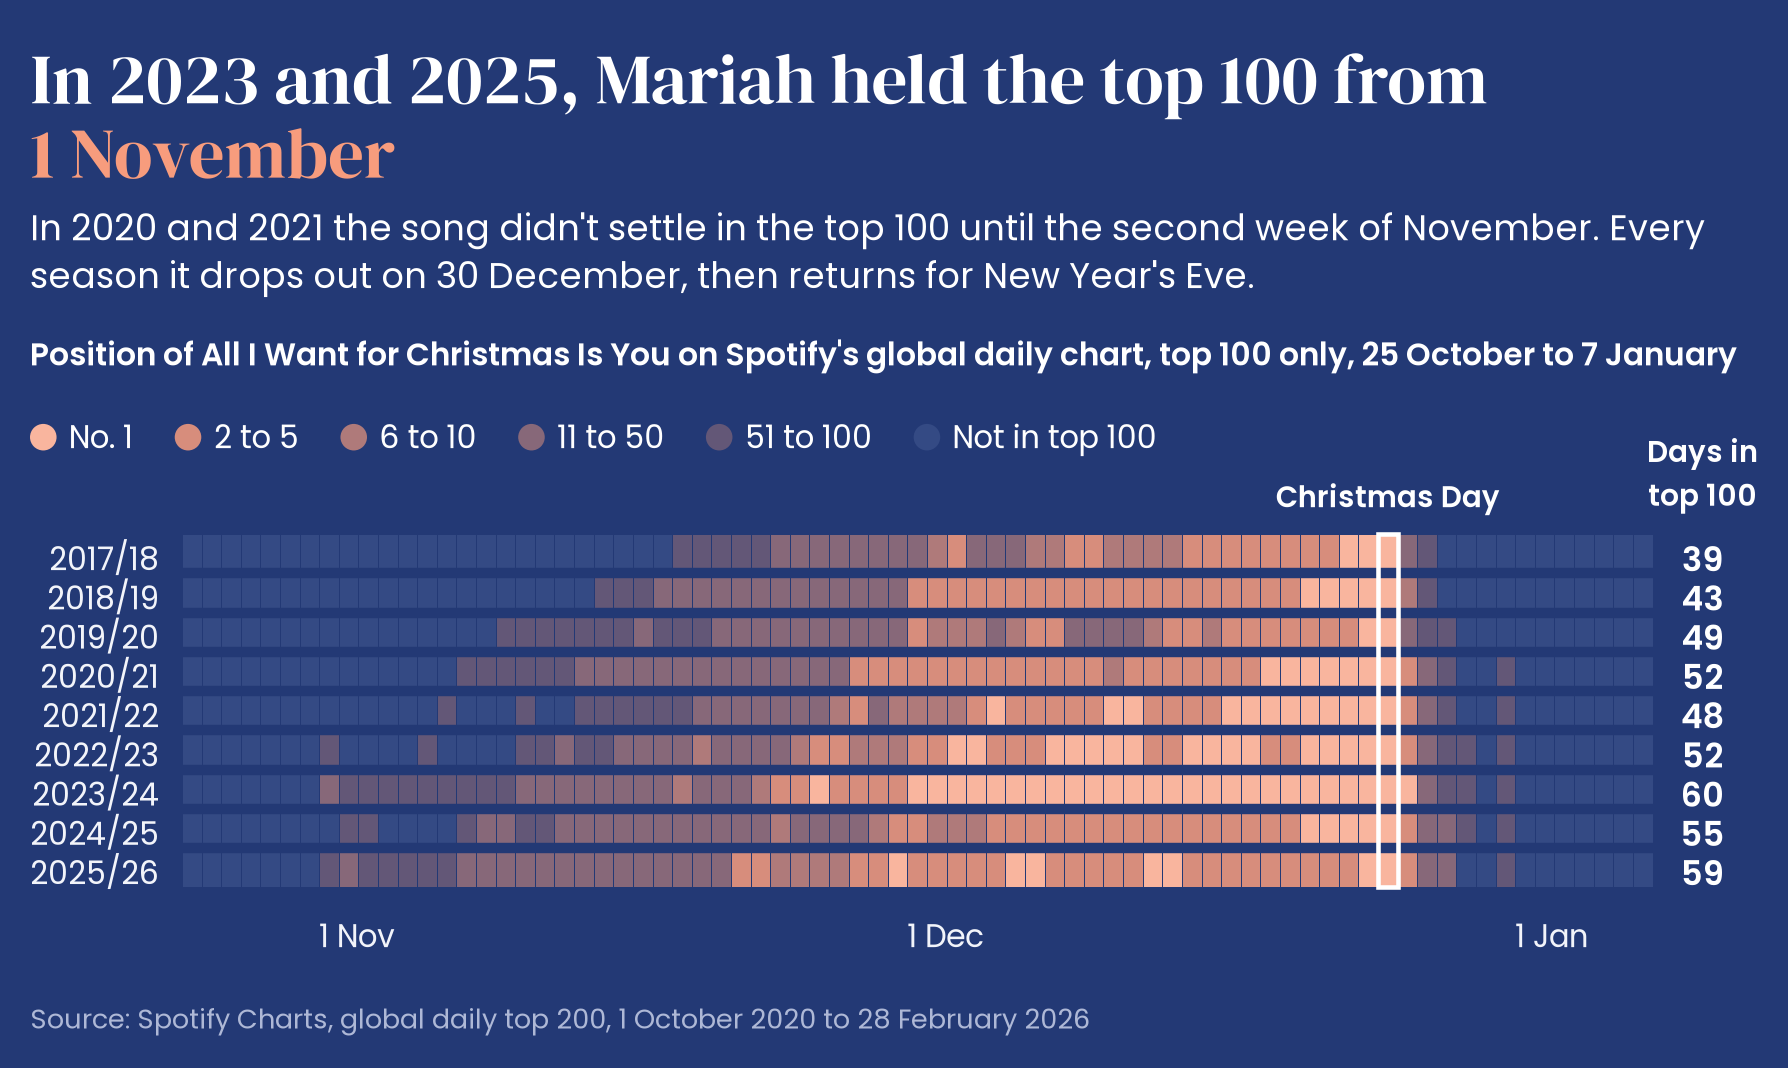

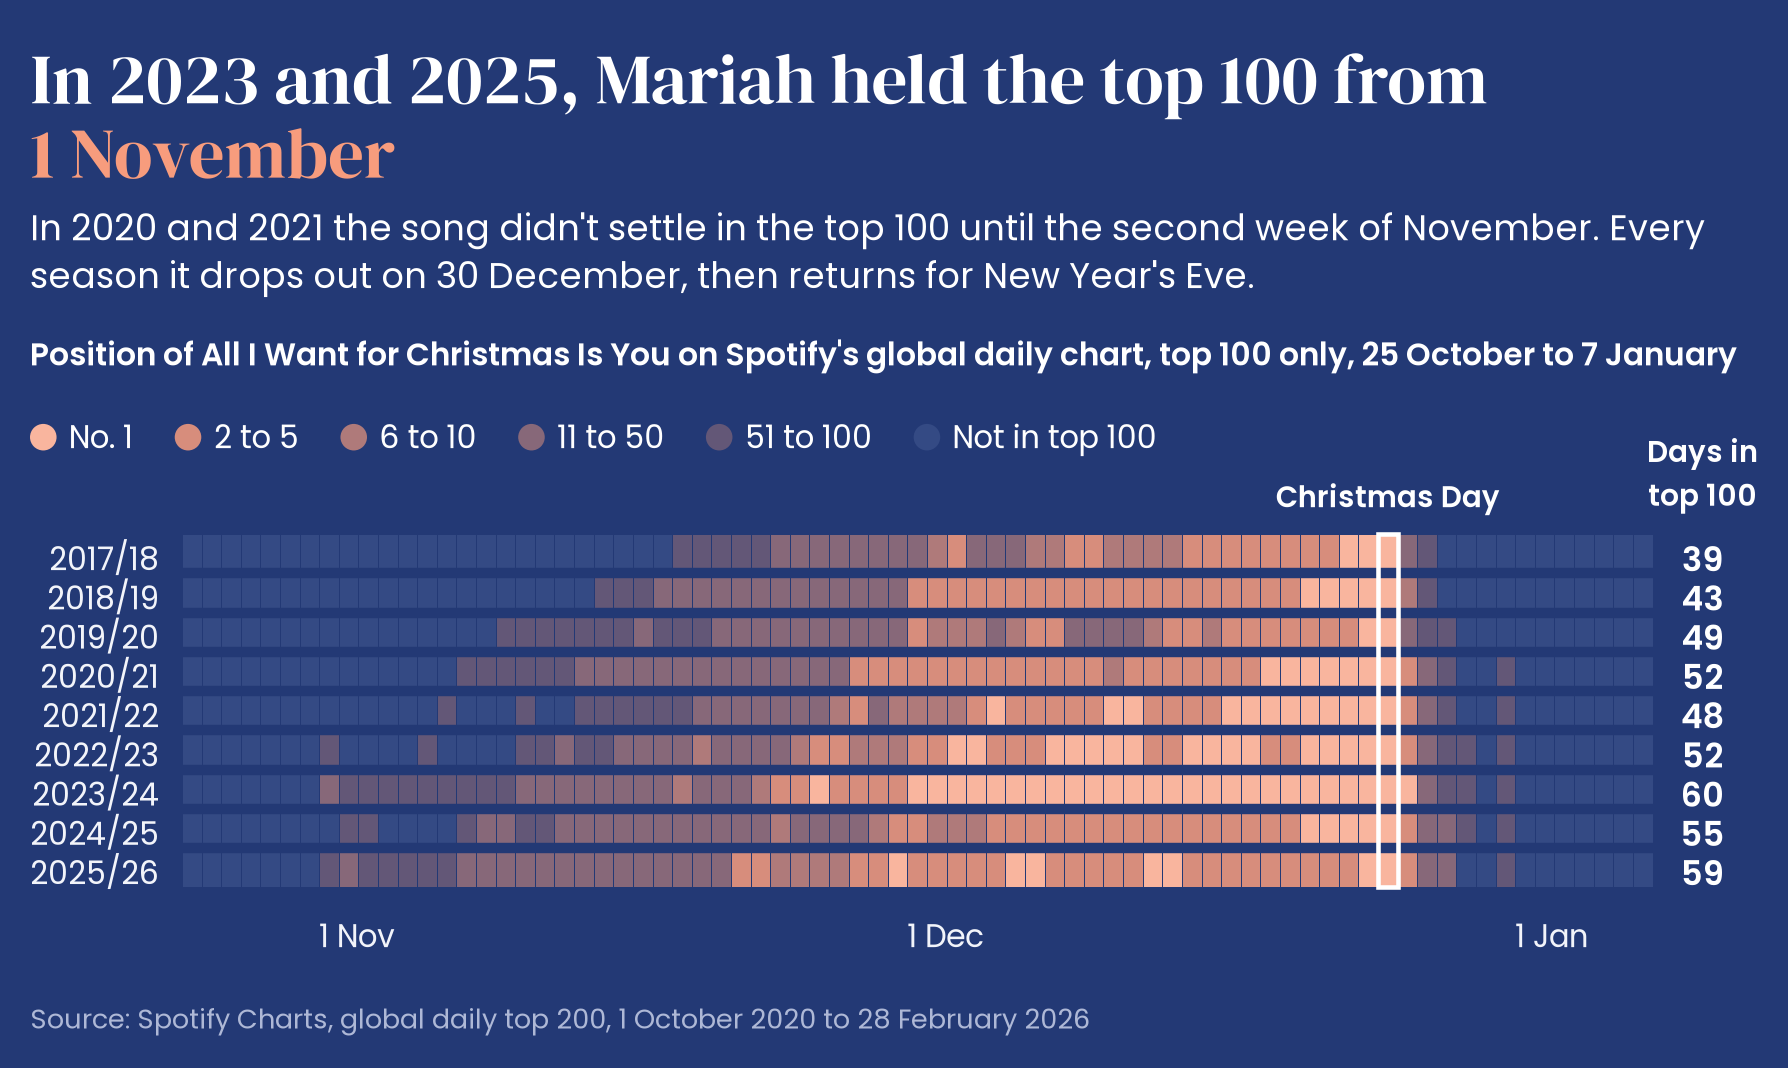

In [ ]:
# Heatmap 1: All I Want for Christmas Is You, position in the top 100
RANK_EDGES = [(1, 2), (2, 6), (6, 11), (11, 51), (51, CUTOFF + 1)]
RANK_LABELS = ["No. 1", "2 to 5", "6 to 10", "11 to 50", "51 to 100"]

# days in the top 100 each season (the whole season, which is the same as the window)
days_in_top_100 = (rank_grid <= CUTOFF).sum(axis=1)

# check the story: first and last day in the top 100, and days in it, each season
in_top = cal[cal["rank"] <= CUTOFF]
print(in_top.groupby("season").agg(first_day=("date", "min"), last_day=("date", "max"),
                                   days_in_top_100=("rank", "size")))

calendar_heatmap(
    to_bands(rank_grid, RANK_EDGES), RANK_LABELS, f"Not in top {CUTOFF}",
    # a non-breaking space keeps "1 November" on one line
    title="In 2023 and 2025, Mariah held the top 100 from *1 November*",
    subtitle="Position of All I Want for Christmas Is You on Spotify's global daily chart, "
             "top 100 only, 25 October to 7 January",
    standfirst="In 2020 and 2021 the song didn't settle in the top 100 until the second week of "
               "November. Every season it drops out on 30 December, then returns for New Year's Eve.",
    path="charts/aiwfc_calendar_heatmap_top100.png",
    side_values=days_in_top_100, side_header="Days in\ntop 100",
)

219 different Christmas tracks reached the top 100
        days_shown  days_whole_season  peak peak_day
season                                              
2017            39                 39  56.0   25 Dec
2018            43                 43  69.0   25 Dec
2019            49                 50  70.0   25 Dec
2020            61                112  82.0   25 Dec
2021            49                 49  83.0   25 Dec
2022            52                 52  78.0   25 Dec
2023            61                 61  84.0   25 Dec
2024            55                 55  84.0   25 Dec
2025            60                 60  86.0   25 Dec


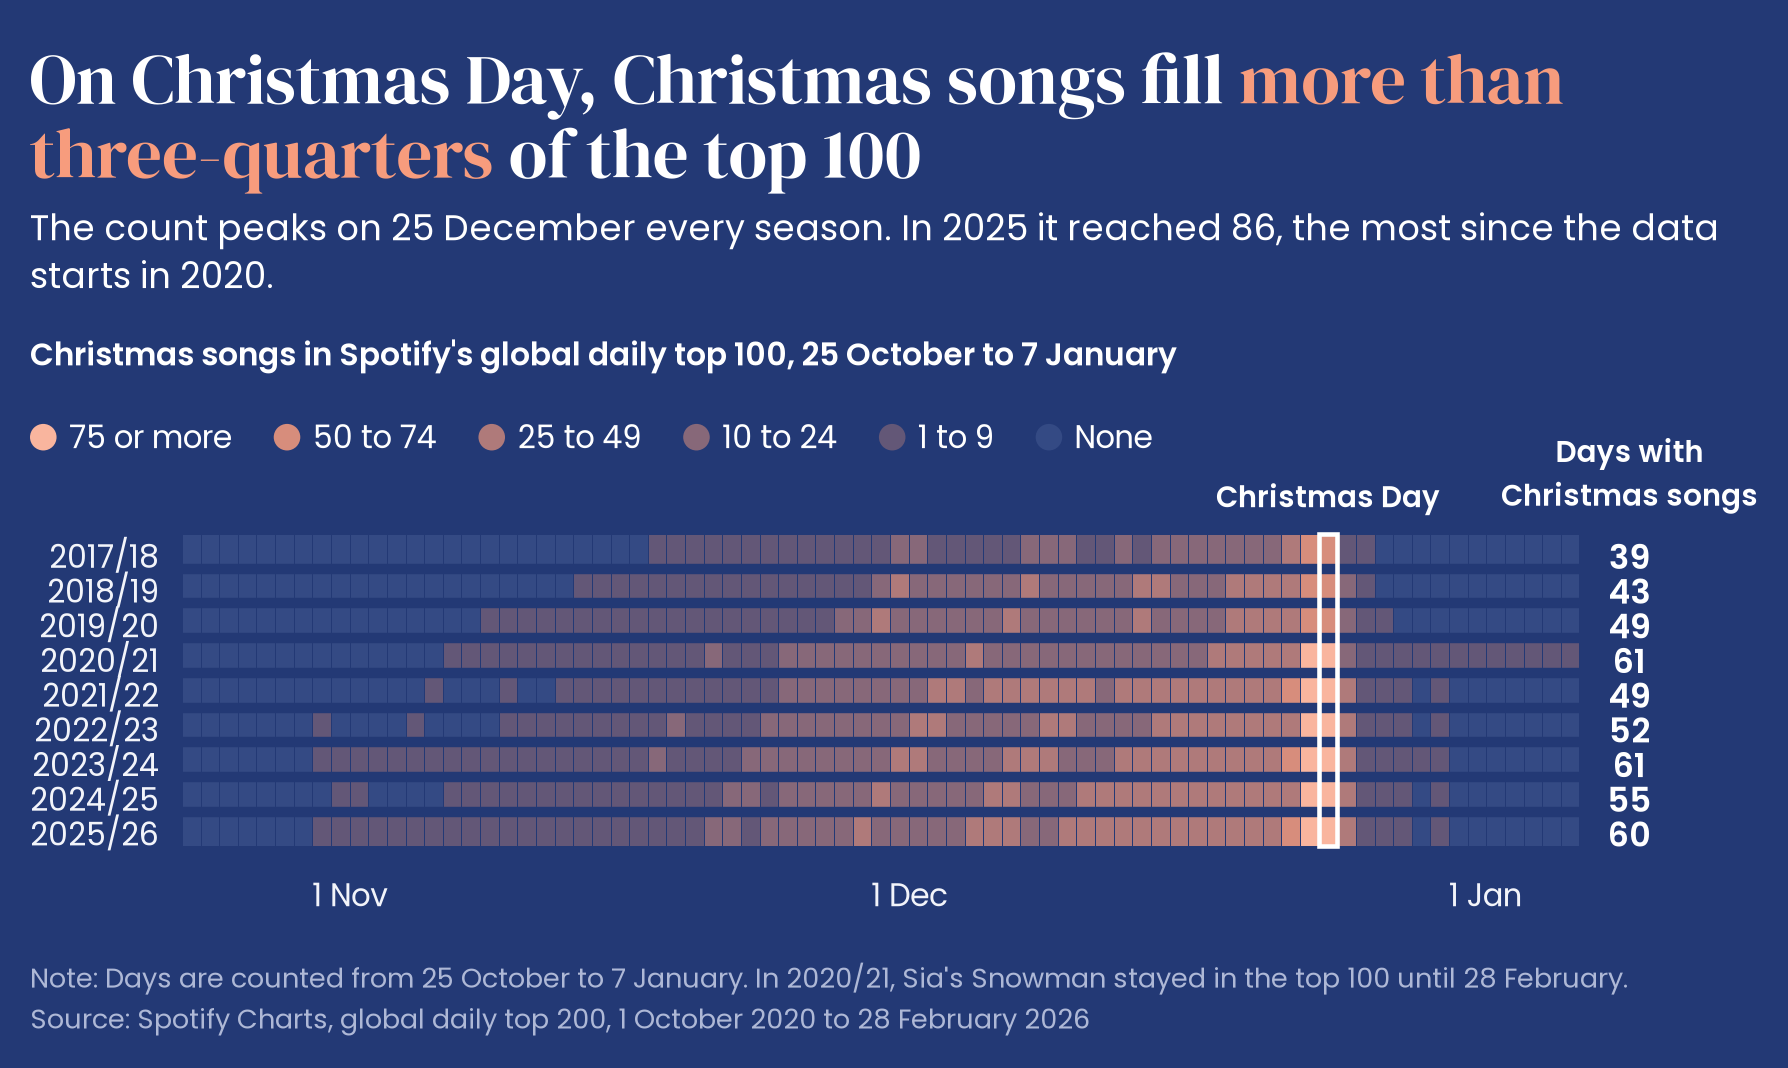

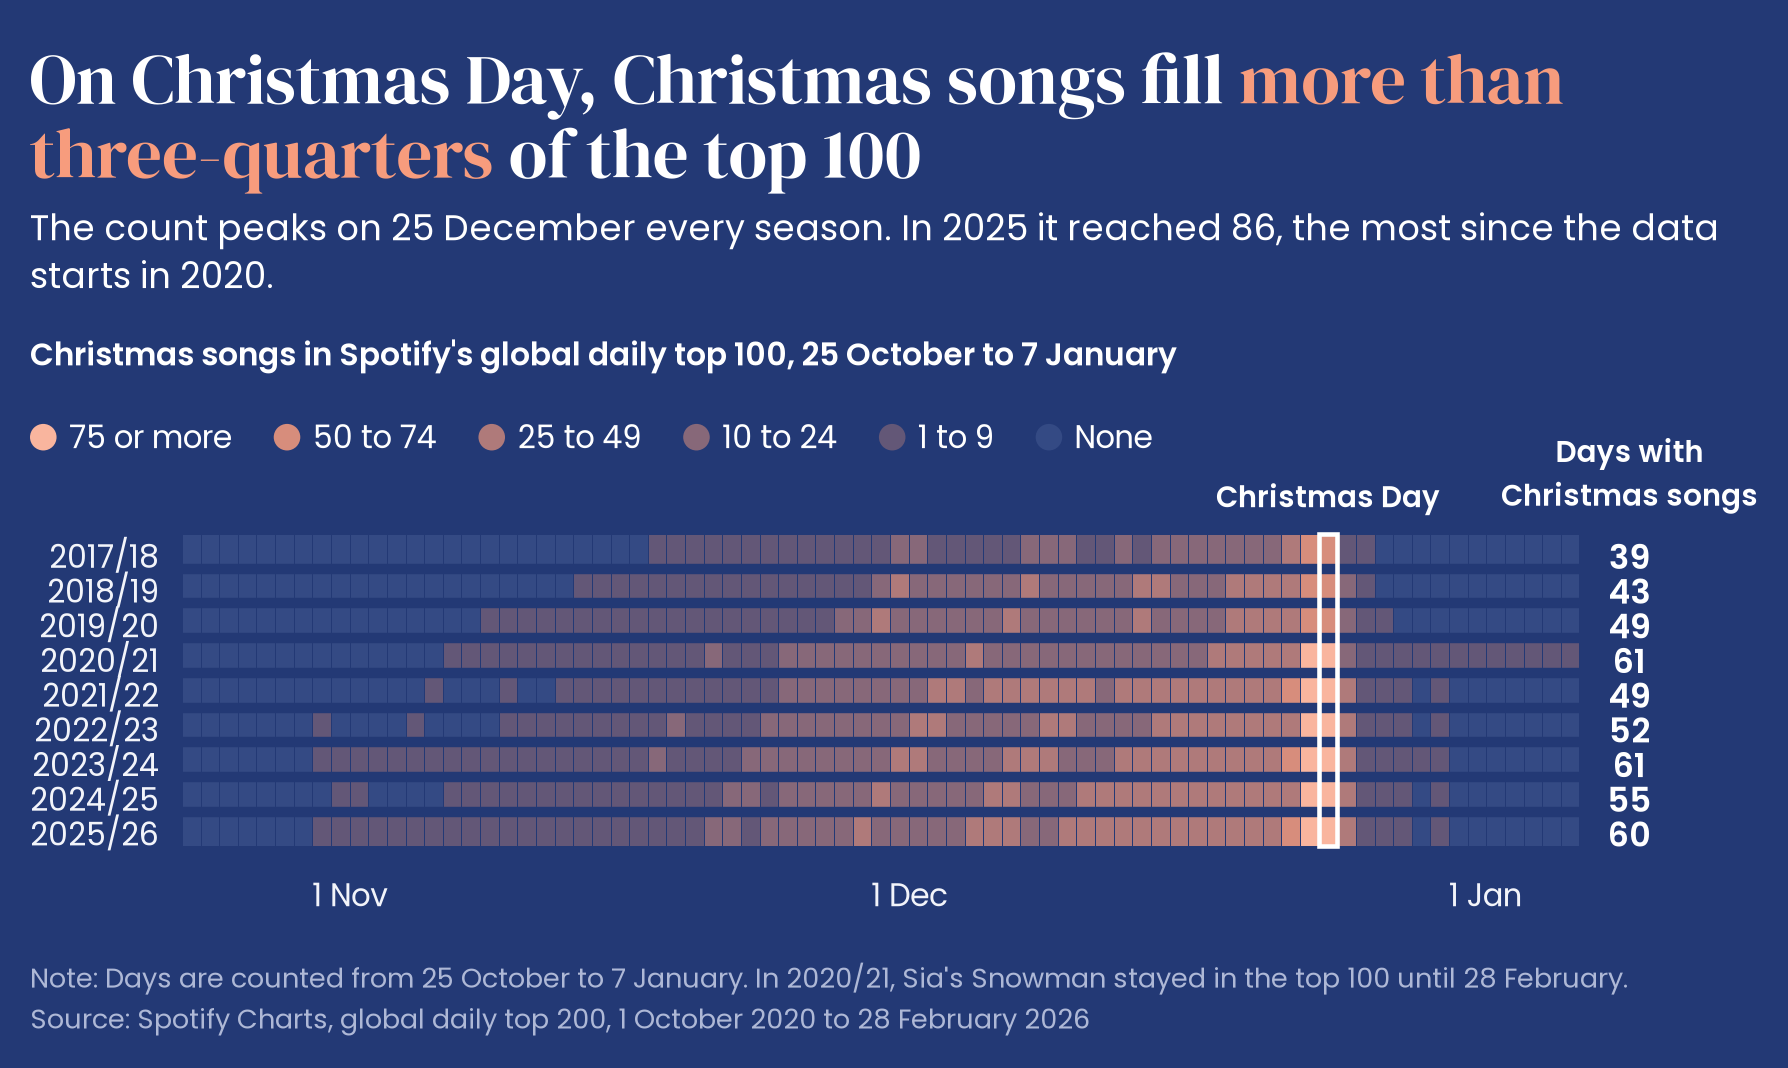

In [ ]:
# Heatmap 2: how many Christmas songs are in the top 100 each day
#
# The data has no genre, so a Christmas song is one with a Christmas word in its title, less a
# few false matches, plus a few seasonal songs whose titles don't say Christmas. Both lists were
# checked by hand against every track that reached the top 100 between 25 Oct and 7 Jan.
XMAS_WORDS = (
    r"christmas|xmas|santa|jingle|navidad|rudolph|sleigh|mistletoe|reindeer|silent night|"
    r"holy night|merry|frosty|joy to the world|deck the hall|little drummer|carol of|grinch|"
    r"wonderful time|let it snow|snowman|winter wonderland|feliz|holiday|o come|noel|tannenbaum|"
    r"do you hear what|saint nick|fairytale of new york|underneath the tree|my only wish|"
    r"mele kalikimaka|cold outside|one more sleep|naughty list|2000 miles|silver bells|"
    r"my kind of present"
)
# titles that match a word above but aren't Christmas songs
# (Feid, Rvssian's Santa, Drake's 7969 Santa, Lil Nas X, Stray Kids, Kesha's Holiday Road)
NOT_XMAS = r"^feliz cumpleaños|^santa$|^7969 santa|^holiday$|^holiday road"
# Christmas songs whose titles give no clue
XMAS_EXTRA = {("Hallelujah", "Pentatonix"), ("I'll Be Home", "Meghan Trainor")}

titles = charts["track_name"].fillna("")
is_xmas = (
    (titles.str.contains(XMAS_WORDS, case=False) & ~titles.str.contains(NOT_XMAS, case=False))
    | pd.Series(list(zip(titles, charts["artists"])), index=charts.index)
        .isin(XMAS_EXTRA)
)
top_100 = charts[charts["rank"] <= CUTOFF]
xmas_per_day = top_100[is_xmas.loc[top_100.index]].groupby("date").size()

cal["xmas_songs"] = cal["date"].map(xmas_per_day).fillna(0)
xmas_grid = cal.pivot(index="season", columns="day", values="xmas_songs")

# days with at least one Christmas song in the top 100, counted over the days the chart shows so
# the number matches its row (2020/21 runs on past the window: Sia's Snowman lasted to 28 Feb)
days_with_xmas = (xmas_grid.loc[:, day_from:day_to] > 0).sum(axis=1)

# check the story: days with a Christmas song (shown and whole season), and each season's peak
print(f"{top_100.loc[is_xmas.loc[top_100.index], 'track_uri'].nunique()} different Christmas "
      "tracks reached the top 100")
print(pd.DataFrame({"days_shown": days_with_xmas, "days_whole_season": (xmas_grid > 0).sum(axis=1),
                    "peak": xmas_grid.max(axis=1), "peak_day": xmas_grid.idxmax(axis=1)
                    .map(lambda d: (SEASON_START + pd.Timedelta(days=int(d))).strftime("%d %b"))}))

XMAS_EDGES = [(75, CUTOFF + 1), (50, 75), (25, 50), (10, 25), (1, 10)]
XMAS_LABELS = ["75 or more", "50 to 74", "25 to 49", "10 to 24", "1 to 9"]

calendar_heatmap(
    to_bands(xmas_grid, XMAS_EDGES), XMAS_LABELS, "None",
    title="On Christmas Day, Christmas songs fill *more than three-quarters* of the top 100",
    subtitle="Christmas songs in Spotify's global daily top 100, 25 October to 7 January",
    standfirst="The count peaks on 25 December every season. In 2025 it reached 86, "
               "the most since the data starts in 2020.",
    path="charts/xmas_songs_calendar_heatmap_top100.png",
    side_values=days_with_xmas, side_header="Days with\nChristmas songs",
    note="Note: Days are counted from 25 October to 7 January. In 2020/21, Sia's Snowman "
         "stayed in the top 100 until 28 February.",
)

## Dumbbell: when Mariah arrives and leaves, region by region

Weekly charts for every region on the charts.spotify.com dropdown, from `pull_spotify_weekly.py`. Each row is one region. The first dot is the start of the first week All I Want for Christmas Is You was in that region's weekly top 200, and the second is the end of its last week. It's drawn in the bwcharts light theme.

In [ ]:
# Dumbbell data: Mariah's first and last week on each region's weekly chart, for one season
WEEKLY_FILE = DATA_DIR / "spotify_weekly_all_regions.csv"
SEASON = 2025                                   # the season starting October 2025

weekly = pd.read_csv(WEEKLY_FILE, parse_dates=["week_end"], dtype={"streams": str},
                     keep_default_na=False, na_values={"rank": [""]})
in_season = weekly["week_end"].between(pd.Timestamp(f"{SEASON}-10-01"),
                                       pd.Timestamp(f"{SEASON + 1}-03-01"))
weekly = weekly[in_season]

# Mariah's original only, matched on title and artist rather than the URI, in case a region
# carries a different release of the same recording. This leaves out the Justin Bieber duet.
is_mariah = ((weekly["track_name"] == "All I Want for Christmas Is You")
             & (weekly["artists"] == "Mariah Carey"))

runs = (weekly[is_mariah].groupby(["region", "region_name"])
        .agg(first_week_end=("week_end", "min"), last_week_end=("week_end", "max"),
             weeks=("week_end", "nunique"), best_rank=("rank", "min"))
        .reset_index())
# a chart week runs Friday to Thursday and is dated by the Thursday, so the song arrives at the
# start of its first week and leaves at the end of its last
runs["arrived"] = runs["first_week_end"] - pd.Timedelta(days=6)
runs["left"] = runs["last_week_end"]
# weeks out of the chart between arriving and leaving (the dumbbell doesn't show these gaps)
runs["weeks_out"] = (runs["last_week_end"] - runs["first_week_end"]).dt.days // 7 + 1 - runs["weeks"]

# hemisphere, by where each country's capital is. Ecuador and Indonesia straddle the equator,
# and both capitals (Quito and Jakarta) are just south of it.
SOUTH = {"ar", "au", "bo", "br", "cl", "ec", "id", "nz", "pe", "py", "uy", "za"}
runs["hemisphere"] = np.where(runs["region"] == "global", "Global",
                              np.where(runs["region"].isin(SOUTH), "South", "North"))

# earliest arrival at the top; regions arriving the same week are ordered by when they left
runs = runs.sort_values(["arrived", "left", "region_name"]).reset_index(drop=True)

never = sorted(set(weekly["region_name"]) - set(runs["region_name"]))
print(f"{len(runs)} regions had the song in their weekly chart, {len(never)} didn't: {', '.join(never) or 'none'}")
print(f"{(runs['weeks_out'] > 0).sum()} regions had weeks out between arriving and leaving")
print(runs.groupby("hemisphere")["arrived"].agg(["count", "min", "median", "max"]))
runs[["region_name", "hemisphere", "arrived", "left", "weeks", "weeks_out", "best_rank"]]

In [ ]:
# Dumbbell plot, in the bwcharts light theme. About 70 regions won't fit one column at 16:9, so
# they're split across three panels, read down each panel in turn, earliest arrival first.
# Each row is coloured by hemisphere: dots, line and region name.
N_PANELS = 3
season_start = pd.Timestamp(f"{SEASON}-10-01")


def days_in(dates):
    """Dates as days since 1 October, so the x axis is plain numbers (as in the heatmaps)."""
    return (pd.Series(dates) - season_start).dt.days.to_numpy()


bw.set_theme("light")
try:
    HEMI_COLOURS = {"North": bw.SECONDARY, "South": bw.PRIMARY, "Global": bw.C8}   # navy, coral, grey
    per_panel = -(-len(runs) // N_PANELS)                            # rows per panel, rounded up

    fig, axes = bw.chart(
        "When does Mariah arrive? *Working title*",                  # rewrite once the data's in
        f"First and last week of All I Want for Christmas Is You in each region's weekly top 200, "
        f"{SEASON}/{str(SEASON + 1)[2:]} season",
        note="Note: Weeks run Friday to Thursday, from the start of the first week in the chart to "
             "the end of the last. Weeks out in between aren't shown. Hemisphere is by capital city.",
        source=f"Source: Spotify Charts, weekly top 200 for {weekly['region'].nunique()} regions",
        size="landscape", ncols=N_PANELS, grid="x", sharex=True,
    )
    fig.subplots_adjust(wspace=0.55)         # room for each panel's region names
    # shorter names for the three longest, so they don't run into the panel to their left
    SHORT = {"United Arab Emirates": "UAE", "Dominican Republic": "Dominican Rep.",
             "Czech Republic": "Czechia"}

    # x axis: from the week before the earliest arrival to the week after the latest exit
    x_from = days_in(runs["arrived"]).min() - 7
    x_to = days_in(runs["left"]).max() + 7
    month_starts = pd.date_range(season_start, season_start + pd.DateOffset(months=5), freq="MS")
    ticks = [d for d in days_in(month_starts) if x_from <= d <= x_to]

    for p, ax in enumerate(axes):
        rows = runs.iloc[p * per_panel:(p + 1) * per_panel].reset_index(drop=True)
        y = np.arange(len(rows))
        start, end = days_in(rows["arrived"]), days_in(rows["left"])
        colours = rows["hemisphere"].map(HEMI_COLOURS).to_list()

        # the line is a lighter tint of the row's colour, so the dots stand out at each end
        ax.hlines(y, start, end, colors=[bw._mix(c, bw.BACKGROUND, 0.6) for c in colours],
                  linewidth=1.4, zorder=1)
        ax.scatter(start, y, s=10, color=colours, zorder=2, clip_on=False)
        ax.scatter(end, y, s=10, color=colours, zorder=3, clip_on=False)

        ax.set_yticks(y, rows["region_name"].replace(SHORT))
        ax.tick_params(axis="y", labelsize=5)
        for label, h in zip(ax.get_yticklabels(), rows["hemisphere"]):
            label.set_color(bw.ink(HEMI_COLOURS[h]))                 # names match their dots
            if h == "Global":
                label.set_fontweight("bold")
        ax.set_ylim(per_panel - 0.5, -1.3)                           # earliest at the top
        ax.set_xlim(x_from, x_to)
        ax.set_xticks(ticks, [f"1 {(season_start + pd.Timedelta(days=int(t))):%b}" for t in ticks])

    # above the top row of the first panel: name each dot
    first = runs.iloc[0]
    for (value,), text in [(days_in([first["arrived"]]), "Arrived"), (days_in([first["left"]]), "Left")]:
        axes[0].annotate(text, xy=(value, 0), xytext=(0, 5), textcoords="offset points",
                         ha="center", va="bottom", fontsize=6, fontweight="semibold",
                         color=bw.TEXT, annotation_clip=False)

    bw.key(axes[0], {"Northern hemisphere": HEMI_COLOURS["North"],
                     "Southern hemisphere": HEMI_COLOURS["South"], "Global": HEMI_COLOURS["Global"]},
           dy=20)

    Path("charts").mkdir(exist_ok=True)
    bw.save(fig, "charts/aiwfc_weekly_dumbbell_regions_light.png")
finally:
    bw.set_theme("navy")                    # so the heatmaps above stay navy if they're re-run